# Exploratory Data Analysis for Finance
## German Credit Risk Dataset — a classroom demo

This notebook is a **demo for students** that walks through the early stages of a machine learning workflow applied to a real finance dataset:

1. Load packages
2. Load the dataset
3. Explore the data (descriptive statistics + visualizations)
4. Clean, transform and select features

> **Note:** This notebook deliberately **stops before training any machine learning model**. The goal here is only to practice loading data, exploring it, and preparing it — model training is a topic for a later class.

The structure follows the standard **seven-step ML development workflow** (Problem Definition → Load Data & Packages → EDA → Data Preparation → Evaluate → Tune → Finalize) — we cover steps 1–4 only.

## About the dataset

**Name:** German Credit Risk dataset (a cleaned subset of the *Statlog (German Credit Data)* dataset from the UCI Machine Learning Repository).

**Source used here:** the companion GitHub repository for the O'Reilly book *"Machine Learning and Data Science Blueprints for Finance"* by Hariom Tatsat, Sahil Puri & Brad Lookabaugh — `tatsat/fin-ml`, file `Chapter 6 - Sup. Learning - Classification models/german_credit_data.csv`.
Original dataset: https://archive.ics.uci.edu/ml/datasets/statlog+(german+credit+data)

**Why this dataset?** It's a realistic, finance-flavored problem: a bank collects information about loan applicants and needs to judge whether each applicant is a good or bad credit risk before approving a loan.

**Size:** 1,000 rows (loan applicants) × 10 columns.

| Column | Type | Description |
|---|---|---|
| `Age` | numeric | Applicant's age, in years |
| `Sex` | categorical | `male` / `female` |
| `Job` | numeric (ordinal) | Skill level, coded 0–3 (0 = unskilled non-resident, 3 = highly skilled) |
| `Housing` | categorical | `own`, `rent`, or `free` |
| `SavingAccounts` | categorical | `little`, `moderate`, `quite rich`, `rich` (missing = no savings account on record) |
| `CheckingAccount` | categorical | `little`, `moderate`, `rich` (missing = no checking account on record) |
| `CreditAmount` | numeric | Requested credit amount (in Deutsche Mark) |
| `Duration` | numeric | Loan duration, in months |
| `Purpose` | categorical | What the loan is for, e.g. `car`, `radio/TV`, `education`, `business` |
| `Risk` | categorical (target-like) | `good` or `bad` credit risk — the outcome a bank would ultimately want to predict |

**Good to know before we start:**
- `SavingAccounts` and `CheckingAccount` contain **genuine missing values** — a realistic data-cleaning challenge.
- `Risk` is not perfectly balanced (there are more "good" than "bad" cases), which is common in credit risk data and worth knowing before any future modeling.

## Step 2.1 — Load packages

Every package below plays a specific role in the workflow. Read the comments.

In [30]:
# %matplotlib inline tells Jupyter to display plots directly under each cell
%matplotlib inline

# --- Core data-handling packages ---
import pandas as pd           # DataFrames: loading, cleaning and exploring tabular data
import numpy as np            # Fast numeric arrays and math operations

# --- Visualization packages ---
import matplotlib.pyplot as plt   # Base plotting library (histograms, boxplots, etc.)
import seaborn as sns             # Higher-level statistical plots, built on top of matplotlib

# --- Preprocessing tools (scikit-learn) ---
from sklearn.preprocessing import LabelEncoder, StandardScaler
# LabelEncoder   -> turns text categories into numbers (e.g. 'good'/'bad' -> 1/0)
# StandardScaler -> rescales numeric columns to mean 0, std dev 1

# --- Feature selection tool (scikit-learn) ---
from sklearn.feature_selection import SelectKBest, f_classif
# SelectKBest + f_classif -> scores each feature on how strongly it relates to the
# target column (Risk), WITHOUT training a predictive model. This is only used
# here to help us decide which features look most informative.

# --- Cosmetic / display settings (optional but makes output easier to read) ---
sns.set_style("whitegrid")                # Clean grid background for all plots
plt.rcParams["figure.figsize"] = (10, 5)  # Default figure size
pd.set_option("display.width", 100)       # Wider console output for DataFrames
pd.set_option("display.max_columns", 20)  # Show all columns when printing

print("All packages loaded successfully.")






All packages loaded successfully.


<div dir="rtl">

**ملاحظتي:** حمّلت المكتبات اللي رح أحتاجها: pandas للتعامل مع الجداول، numpy للحسابات، matplotlib و seaborn للرسومات، و sklearn لتجهيز البيانات واختيار الـ features. الأسطر اللي بتبلش بـ # هي تعليقات للشرح وما بتنفّذ.

</div>

## Step 2.2 — Load the dataset

In [31]:
# The CSV sits in the same folder as this notebook.
# (Original source, if you ever need to re-download it:
#  https://raw.githubusercontent.com/tatsath/fin-ml/master/Chapter%206%20-%20Sup.%20Learning%20-%20Classification%20models/german_credit_data.csv)
DATA_PATH = "german_credit_data.csv"

# read_csv loads the file into a pandas DataFrame -- the standard table-like
# structure we will use for the rest of this notebook.
dataset = pd.read_csv(DATA_PATH)

print(f"Dataset loaded: {dataset.shape[0]} rows, {dataset.shape[1]} columns")

Dataset loaded: 1000 rows, 10 columns


<div dir="rtl">

**ملاحظتي:** قرأت ملف الـ CSV باستخدام `pd.read_csv` وحطيته بجدول اسمه `dataset`. البيانات فيها 1000 صف (كل صف شخص طالب قرض) و 10 أعمدة.

</div>

# Step 3 — Exploratory Data Analysis (EDA)
## 3.1 Descriptive statistics

Before doing anything else with a new dataset, we should always look at it: how big is it, what type is each column, are there missing values, and what do the numbers roughly look like?

In [32]:
# .head() shows the first few rows so we can eyeball what the raw data looks like
dataset.head()

,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


<div dir="rtl">

**ملاحظتي:** `head()` بيعرض أول 5 صفوف عشان أشوف شكل البيانات. لاحظت إنه في أعمدة أرقام (زي Age) وأعمدة نصوص (زي Sex)، وإنه في خانات مكتوب فيها **NaN** يعني قيم ناقصة.

</div>

In [33]:
# .shape tells us (rows, columns) -- a quick sanity check on dataset size
print("Shape (rows, columns):", dataset.shape)

Shape (rows, columns): (1000, 10)


<div dir="rtl">

**ملاحظتي:** `shape` بيعطي حجم البيانات (عدد الصفوف، عدد الأعمدة) = (1000, 10)، يعني البيانات انقرأت كاملة.

</div>

In [34]:
# .dtypes shows the data type Python/pandas assigned to each column.
# Numeric columns should show int64/float64; text columns show 'object'.
dataset.dtypes

Age                 int64
Sex                object
Job                 int64
Housing            object
SavingAccounts     object
CheckingAccount    object
CreditAmount        int64
Duration            int64
Purpose            object
Risk               object
dtype: object

<div dir="rtl">

**ملاحظتي:** `dtypes` بيوضح نوع كل عمود. الأعمدة الرقمية (Age, Job, CreditAmount, Duration) نوعها int64، والباقي نصوص (object). هاد مهم لأنه الموديل لاحقاً بيحتاج كل إشي أرقام.

</div>

In [35]:
# .describe() summarizes the NUMERIC columns: count, mean, std, min, quartiles, max.
# This is a fast way to spot obvious problems (e.g. a negative age, an
# unreasonably large credit amount) and to understand typical value ranges.
dataset.describe()

,Age,Job,CreditAmount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


<div dir="rtl">

**ملاحظتي:** `describe()` بيعطي ملخص إحصائي للأعمدة الرقمية. متوسط العمر حوالي 35.5 سنة، ومتوسط القرض 3271. لاحظت إنه متوسط CreditAmount أكبر من الوسيط (2319.5) وأعلى قيمة 18424، وهاد معناه إنه في قروض كبيرة جداً (outliers) والتوزيع ملتوي لليمين.

</div>

In [36]:
# describe(exclude="number") gives the equivalent summary for CATEGORICAL columns:
# how many non-missing values, how many unique categories, and the most common one.
dataset.describe(exclude="number")

,Sex,Housing,SavingAccounts,CheckingAccount,Purpose,Risk
count,1000,1000,817,606,1000,1000
unique,2,3,4,3,8,2
top,male,own,little,little,car,good
freq,690,713,603,274,337,700


<div dir="rtl">

**ملاحظتي:** هاد ملخص للأعمدة النصية. أغلب المتقدمين ذكور (690)، وأكثر هدف للقرض هو السيارة (car). عمود SavingAccounts فيه 817 قيمة بس بدل 1000، يعني في قيم ناقصة.

</div>

In [37]:
# isna().sum() counts missing values per column -- essential before any modeling.
missing_counts = dataset.isna().sum()
print("Missing values per column:\n")
print(missing_counts)

Missing values per column:

Age                  0
Sex                  0
Job                  0
Housing              0
SavingAccounts     183
CheckingAccount    394
CreditAmount         0
Duration             0
Purpose              0
Risk                 0
dtype: int64


<div dir="rtl">

**ملاحظتي:** في عمودين بس فيهم قيم ناقصة: SavingAccounts (183) و CheckingAccount (394). باقي الأعمدة كاملة.

</div>

In [38]:
# A quick look at the target-like column 'Risk': how many good vs. bad cases?
# Knowing this balance matters a lot for any future modeling step.
print(dataset["Risk"].value_counts())
print()
print(dataset["Risk"].value_counts(normalize=True).round(3) * 100, "% of total")

Risk
good    700
bad     300
Name: count, dtype: int64

Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64 % of total


<div dir="rtl">

**ملاحظتي:** 700 شخص good (70%) و 300 bad (30%). يعني البيانات **غير متوازنة**، وهاد لازم أنتبه إله لما أبني موديل، لأنه الـ accuracy لحالها ممكن تكون مضللة.

</div>

### Figure — missing values by column

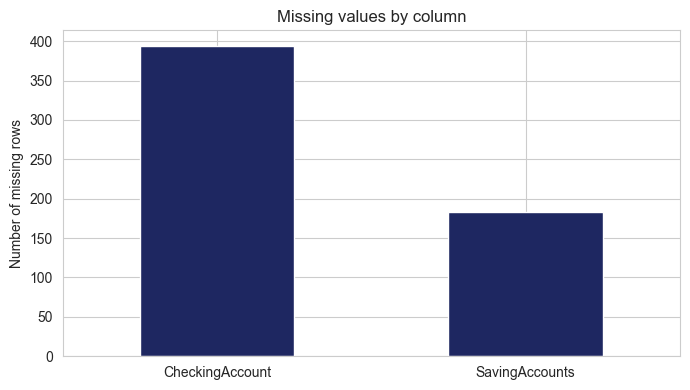

In [39]:
# A simple bar chart makes missing data much easier to spot than a printed table.
missing_counts = dataset.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

plt.figure(figsize=(7, 4))
missing_counts.plot(kind="bar", color="#1E2761")
plt.title("Missing values by column")
plt.ylabel("Number of missing rows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Interpretation: SavingAccounts and CheckingAccount are the only columns with
# missing values. For this dataset, a missing account entry most likely means the
# applicant simply doesn't have that type of account -- we'll handle this in the
# data-cleaning section below rather than dropping these rows.

<div dir="rtl">

**ملاحظتي:** الرسمة بتوضح إنه CheckingAccount فيه قيم ناقصة أكثر بكثير من SavingAccounts. الرسمة أوضح من الجدول لأني بشوف الفرق بعيني مباشرة.

</div>

## 3.2 Data visualization

### Univariate plots

Study each attribute on its own first -- this is the fastest way to learn what a dataset actually looks like before comparing variables to each other.

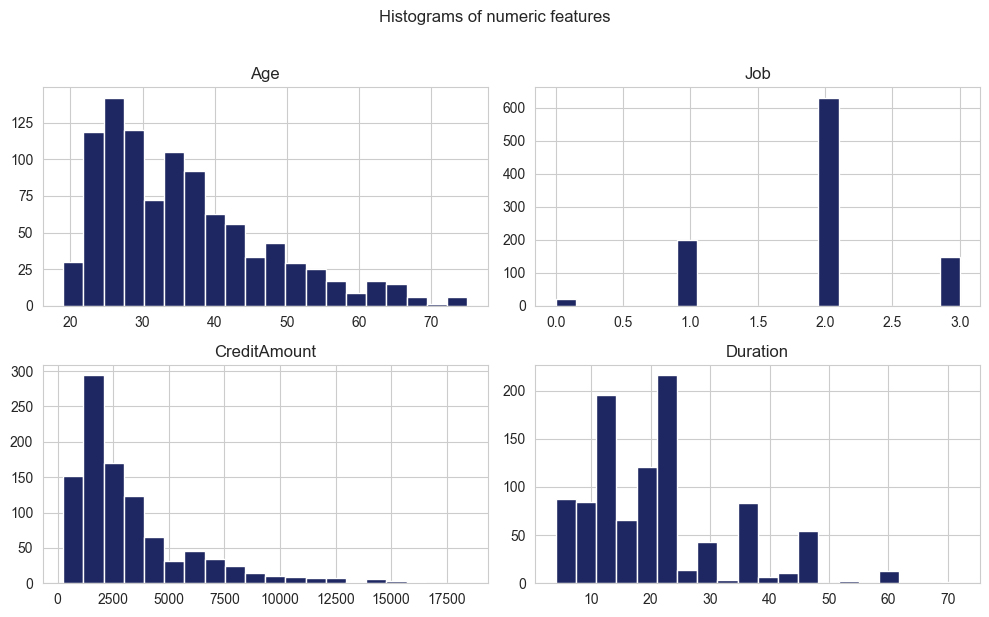

In [40]:
# Histograms for the numeric columns: shows the SHAPE of each distribution
# (is it roughly symmetric? skewed? are there obvious outliers on one side?)
numeric_cols = ["Age", "Job", "CreditAmount", "Duration"]

dataset[numeric_cols].hist(figsize=(10, 6), bins=20, color="#1E2761", edgecolor="white")
plt.suptitle("Histograms of numeric features", y=1.02)
plt.tight_layout()
plt.show()

<div dir="rtl">

**ملاحظتي:** الـ histogram بيوضح توزيع كل عمود. العمر والقرض ملتويين لليمين (right-skewed)، يعني أغلب الناس شباب وأغلب القروض صغيرة، مع قليل من القيم الكبيرة. عمود Job أغلب قيمه 2.

</div>

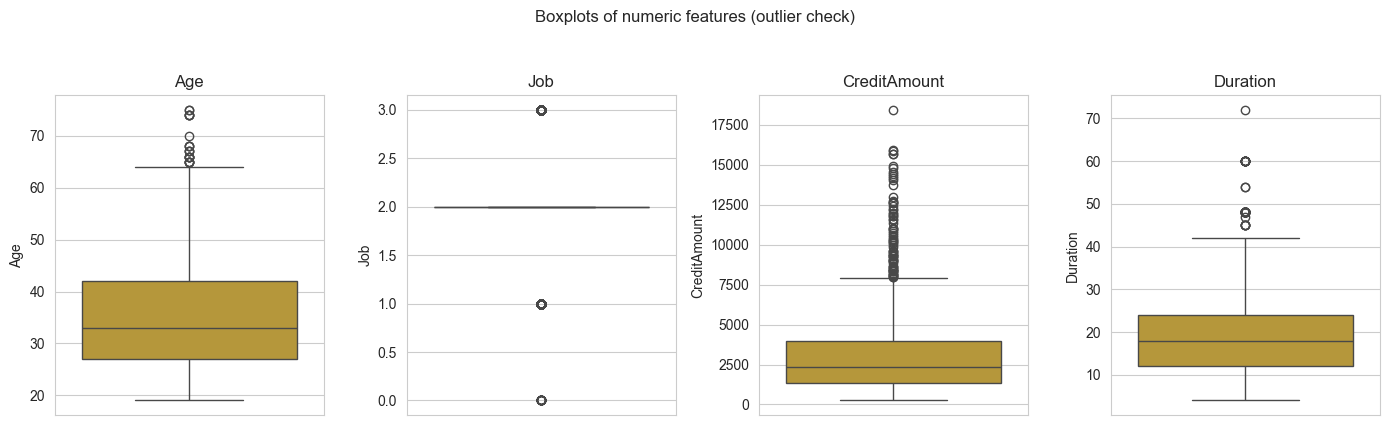

In [41]:
# Boxplots are a fast way to spot outliers: the box shows the middle 50% of
# values, the whiskers show the typical range, and dots beyond that are outliers.
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(14, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=dataset[col], ax=ax, color="#C9A227")
    ax.set_title(col)
plt.suptitle("Boxplots of numeric features (outlier check)", y=1.05)
plt.tight_layout()
plt.show()

# Interpretation: CreditAmount and Duration both show a right-skewed distribution
# with several high-value outliers -- large loans are less common but do occur.

<div dir="rtl">

**ملاحظتي:** الـ boxplot بيبيّن القيم الشاذة (outliers) كدوائر فوق الصندوق. CreditAmount فيه outliers كثير، يعني في قروض كبيرة جداً بس قليلة.

</div>

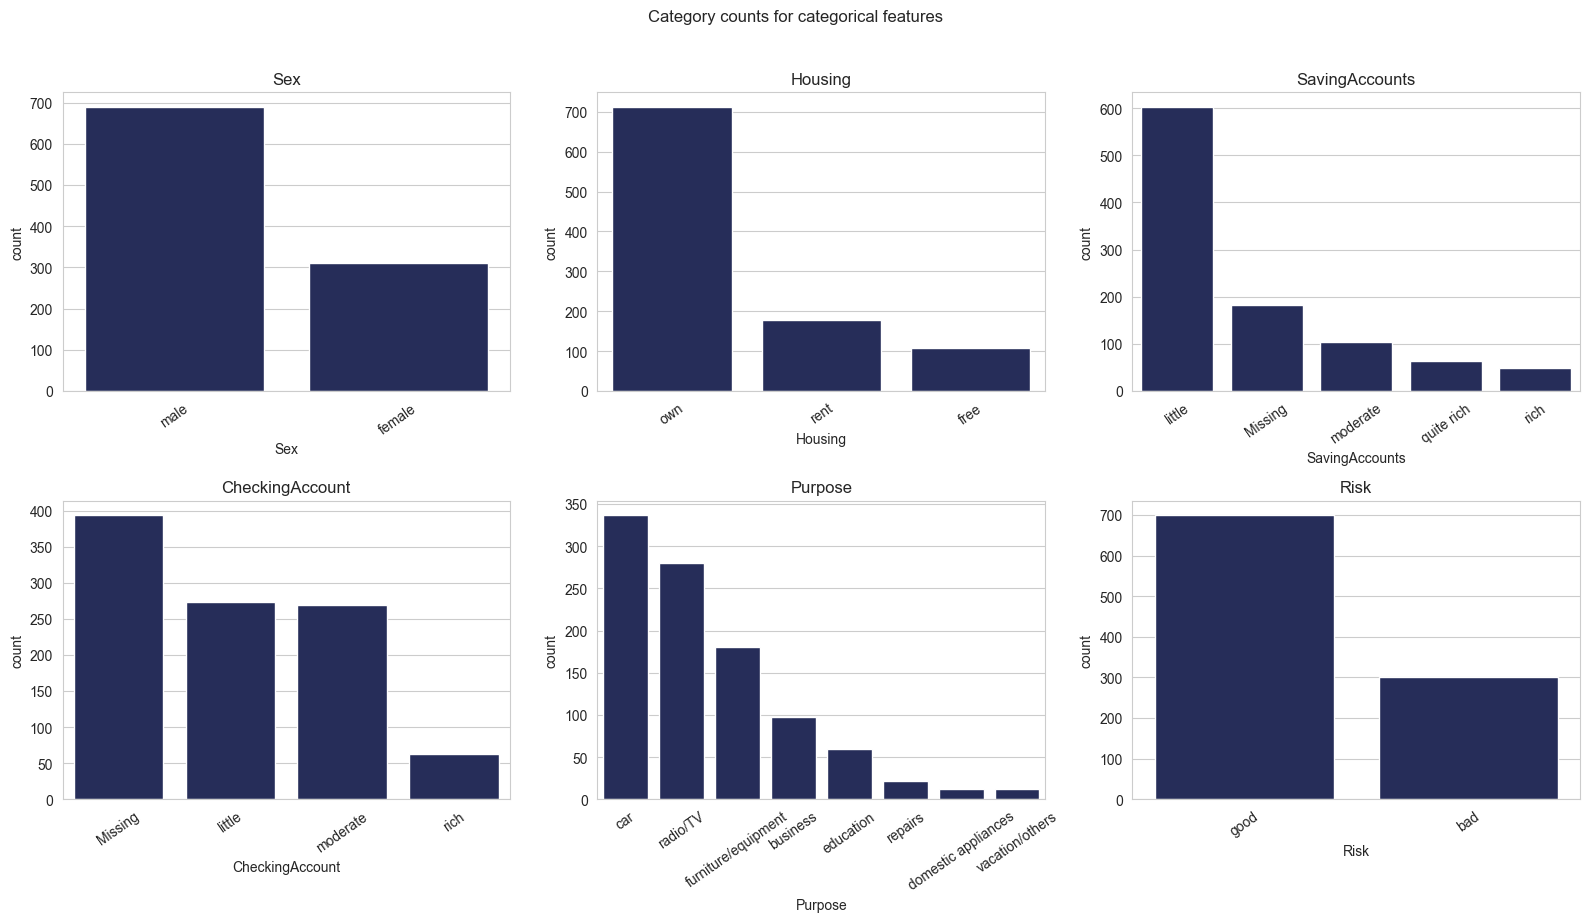

In [42]:
# Count plots for the categorical columns: how many rows fall into each category?
categorical_cols = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for ax, col in zip(axes, categorical_cols):
    # Fill missing values with the string "Missing" so they show up as their own
    # bar instead of being silently dropped by the plotting library.
    col_data = dataset[col].fillna("Missing")
    # order=... sorts bars from most to least common, which is easier to read
    order = col_data.value_counts().index
    sns.countplot(x=col_data, order=order, ax=ax, color="#1E2761")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=35)
plt.suptitle("Category counts for categorical features", y=1.02)
plt.tight_layout()
plt.show()

<div dir="rtl">

**ملاحظتي:** هاي الرسومات بتعد كم شخص بكل فئة للأعمدة النصية. أغلب الناس ذكور وبيملكوا بيوتهم (own)، وأغلب القروض لسيارة أو راديو/تلفزيون. عوّضت القيم الناقصة بكلمة Missing عشان تظهر بالرسمة.

</div>

### Multivariate plots

Now look at relationships **between** variables -- this is where useful patterns for a future model usually show up.

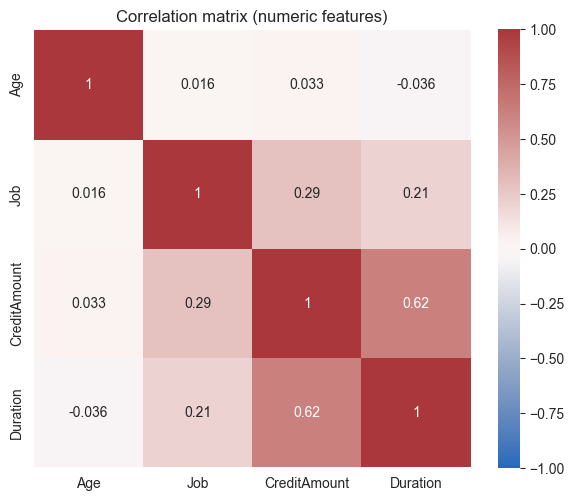

In [43]:
# Correlation heatmap: how strongly are the NUMERIC features related to each other?
# Values close to +1 or -1 mean two features move together strongly;
# values near 0 mean little to no linear relationship.
plt.figure(figsize=(6, 5))
correlation = dataset[numeric_cols].corr()
sns.heatmap(correlation, vmin=-1, vmax=1, annot=True, cmap="vlag", square=True)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.show()

<div dir="rtl">

**ملاحظتي:** الـ correlation بيقيس العلاقة بين كل عمودين (من -1 لـ +1). أقوى علاقة هي بين CreditAmount و Duration (0.62)، يعني كل ما القرض أكبر بتكون مدته أطول. العمر تقريباً ما إله علاقة بحجم القرض (0.033).

</div>

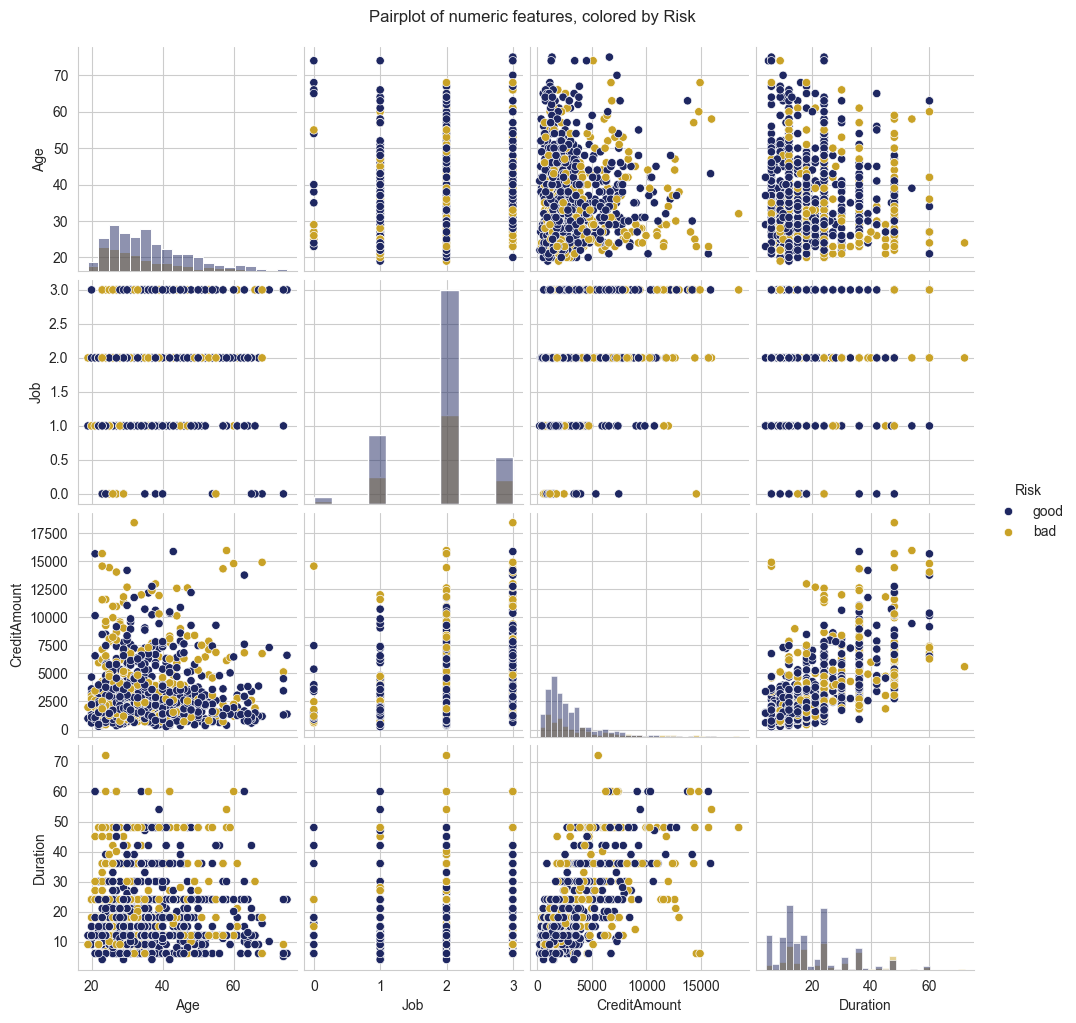

In [44]:
# A pairplot ("scatterplot matrix") plots every numeric feature against every
# other one, colored by Risk -- a fast way to see whether good/bad risk cases
# separate visually along any pair of features.
sns.pairplot(dataset, vars=numeric_cols, hue="Risk",
             palette={"good": "#1E2761", "bad": "#C9A227"}, diag_kind="hist")
plt.suptitle("Pairplot of numeric features, colored by Risk", y=1.02)
plt.show()

<div dir="rtl">

**ملاحظتي:** الـ pairplot بيرسم كل عمودين مع بعض، ولوّن النقاط حسب Risk (أزرق good وذهبي bad). النقاط متداخلة كثير، يعني ما في عمود لحاله بيفصل بين good و bad بشكل واضح.

</div>

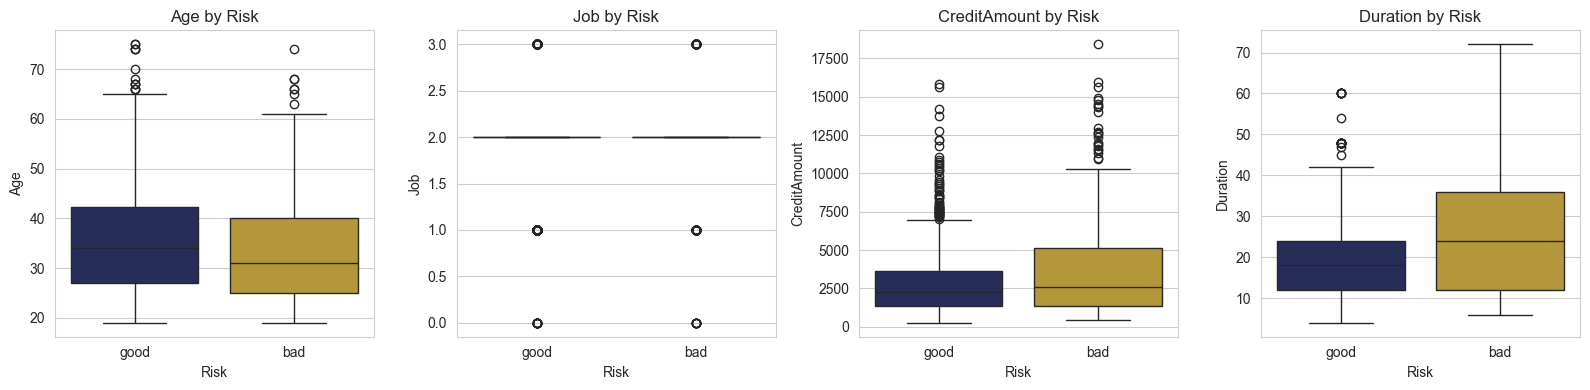

In [45]:
# Boxplots grouped by Risk: does the DISTRIBUTION of a numeric feature look
# different for 'good' vs 'bad' risk applicants? A visible difference suggests
# that feature could be informative for a future model.
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(16, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=dataset, x="Risk", y=col, hue="Risk",
                palette={"good": "#1E2761", "bad": "#C9A227"}, legend=False, ax=ax)
    ax.set_title(f"{col} by Risk")
plt.tight_layout()
plt.show()

# Interpretation: 'bad' risk applicants tend to have somewhat higher CreditAmount
# and Duration -- larger, longer loans look riskier, which matches financial
# intuition.

<div dir="rtl">

**ملاحظتي:** قارنت كل عمود بين good و bad. الأشخاص الـ bad عندهم قروض أكبر ومدتها أطول، وهاد منطقي مالياً: القرض الأكبر والأطول خطره أعلى.

</div>

# Step 4 — Data Preparation

## 4.1 Data cleaning — handling missing values

We saw earlier that `SavingAccounts` and `CheckingAccount` have missing values. For this dataset, a missing entry most likely means the applicant does not have that type of account at all -- so instead of dropping rows (which would throw away otherwise-good data), we'll fill the missing values with an explicit `"none"` category.

In [46]:
# Work on a copy so the original raw dataset stays untouched for reference.
df_clean = dataset.copy()

# Fill missing values with an explicit "none" category (domain-informed choice --
# see markdown above). This keeps every row usable instead of dropping ~40% of
# the data (394 rows are missing CheckingAccount alone).
df_clean["SavingAccounts"] = df_clean["SavingAccounts"].fillna("none")
df_clean["CheckingAccount"] = df_clean["CheckingAccount"].fillna("none")

# Double-check: there should be zero missing values left anywhere in the dataset.
print("Remaining missing values:\n")
print(df_clean.isna().sum())

Remaining missing values:

Age                0
Sex                0
Job                0
Housing            0
SavingAccounts     0
CheckingAccount    0
CreditAmount       0
Duration           0
Purpose            0
Risk               0
dtype: int64


<div dir="rtl">

**ملاحظتي:** بدل ما أحذف الصفوف اللي فيها قيم ناقصة (كنت رح أخسر حوالي 40% من البيانات)، عبّيتها بكلمة "none"، لأنه القيمة الناقصة غالباً معناها إنه الشخص ما عنده هاد النوع من الحسابات. عملت نسخة `copy()` عشان الأصل يضل زي ما هو. بعد التنظيف ما ضل ولا قيمة ناقصة.

</div>

## 4.2 Data transformation — encoding & scaling

Machine learning tools generally expect **numbers**, not text, and often work better when numeric features share a similar scale. So we:

1. **Encode** categorical (text) columns into numbers.
2. **Scale** numeric columns so no single feature dominates just because of its raw magnitude (e.g. `CreditAmount` is in the thousands, `Job` is 0–3).

In [47]:
# --- Encode categorical columns ---
# LabelEncoder assigns each category an integer code, e.g. 'good'/'bad' -> 1/0.
# (For features with no natural order, one-hot encoding is often preferred over
# label encoding before modeling -- we use LabelEncoder here purely to keep this
# preprocessing demo simple and inspectable.)
df_encoded = df_clean.copy()
categorical_cols_all = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

encoders = {}  # keep the fitted encoders in case we need to decode values later
for col in categorical_cols_all:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_clean[col])
    encoders[col] = le
    print(f"{col:16s} -> {list(le.classes_)}")

Sex              -> ['female', 'male']
Housing          -> ['free', 'own', 'rent']
SavingAccounts   -> ['little', 'moderate', 'none', 'quite rich', 'rich']
CheckingAccount  -> ['little', 'moderate', 'none', 'rich']
Purpose          -> ['business', 'car', 'domestic appliances', 'education', 'furniture/equipment', 'radio/TV', 'repairs', 'vacation/others']
Risk             -> ['bad', 'good']


<div dir="rtl">

**ملاحظتي:** الموديلات بتفهم أرقام بس، فحوّلت كل الأعمدة النصية لأرقام باستخدام `LabelEncoder`. كل فئة بتاخد رقم حسب الترتيب الأبجدي، مثلاً Risk: bad = 0 و good = 1، و Sex: female = 0 و male = 1.

</div>

In [48]:
# --- Scale numeric columns ---
# StandardScaler transforms each numeric column to have mean 0 and std dev 1.
scaler = StandardScaler()
numeric_cols_to_scale = ["Age", "Job", "CreditAmount", "Duration"]

df_scaled = df_encoded.copy()
df_scaled[numeric_cols_to_scale] = scaler.fit_transform(df_encoded[numeric_cols_to_scale])

# Compare a couple of rows before vs. after scaling, to see what changed.
print("Before scaling:")
print(df_encoded[numeric_cols_to_scale].head(3))
print("\nAfter scaling (mean ~0, std ~1):")
print(df_scaled[numeric_cols_to_scale].head(3).round(3))

Before scaling:
   Age  Job  CreditAmount  Duration
0   67    2          1169         6
1   22    2          5951        48
2   49    1          2096        12

After scaling (mean ~0, std ~1):
     Age    Job  CreditAmount  Duration
0  2.766  0.147        -0.745    -1.236
1 -1.191  0.147         0.950     2.248
2  1.183 -1.384        -0.417    -0.739


<div dir="rtl">

**ملاحظتي:** الأعمدة كانت بمقاييس مختلفة كثير (القرض بالآلاف والـ Job من 0 لـ 3). `StandardScaler` بيحوّل كل عمود بحيث متوسطه 0 وانحرافه 1، عشان ولا عمود يسيطر بس لأنه أرقامه كبيرة. مثلاً عمر 67 صار 2.766 لأنه أكبر من المتوسط بكثير.

</div>

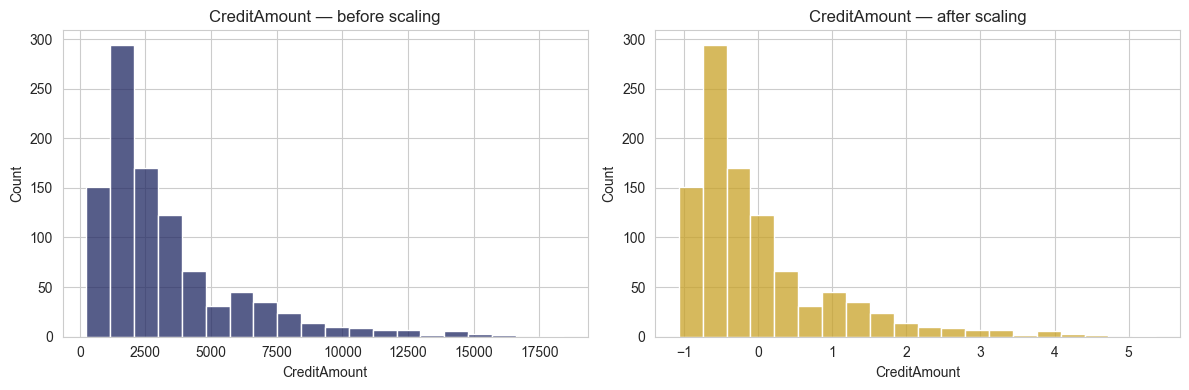

In [49]:
# Visual check: scaling changes the AXIS, not the SHAPE, of a distribution.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_encoded["CreditAmount"], bins=20, ax=axes[0], color="#1E2761")
axes[0].set_title("CreditAmount — before scaling")
sns.histplot(df_scaled["CreditAmount"], bins=20, ax=axes[1], color="#C9A227")
axes[1].set_title("CreditAmount — after scaling")
plt.tight_layout()
plt.show()

<div dir="rtl">

**ملاحظتي:** الرسمتين نفس الشكل بالزبط، الفرق بس بالأرقام عالمحور. يعني الـ scaling بيغير المقياس بس وما بيغير شكل التوزيع.

</div>

## 4.3 Feature selection

Now that every column is numeric, we can score each feature on how strongly it relates to `Risk`. This does **not** train a predictive model -- it only ranks features, which is useful information before modeling begins in a later class.

In [50]:
# Separate the features (X) from the target-like column (y).
X = df_scaled.drop(columns=["Risk"])
y = df_scaled["Risk"]

# SelectKBest + f_classif scores every feature with an ANOVA F-test: a higher
# score means the feature's values differ more between the 'good' and 'bad'
# Risk groups -- i.e., it looks more informative.
selector = SelectKBest(score_func=f_classif, k="all")   # k="all" -> score every feature, keep none/drop none yet
selector.fit(X, y)

feature_scores = pd.DataFrame({
    "Feature": X.columns,
    "Score": selector.scores_
}).sort_values("Score", ascending=False).reset_index(drop=True)

feature_scores

,Feature,Score
0,CheckingAccount,111.721482
1,Duration,48.333790
2,SavingAccounts,33.948465
3,CreditAmount,24.482366
4,Age,8.356995
5,Sex,5.720350
6,Purpose,3.745234
7,Job,1.070584
8,Housing,0.372463


<div dir="rtl">

**ملاحظتي:** فصلت البيانات لـ X (الـ features) و y (عمود Risk). `SelectKBest` مع `f_classif` بيعطي كل feature علامة حسب قديش بيفرق بين good و bad. أهم feature هو CheckingAccount (111.7) وبعده Duration (48.3)، وأقلهم Housing (0.37).

</div>

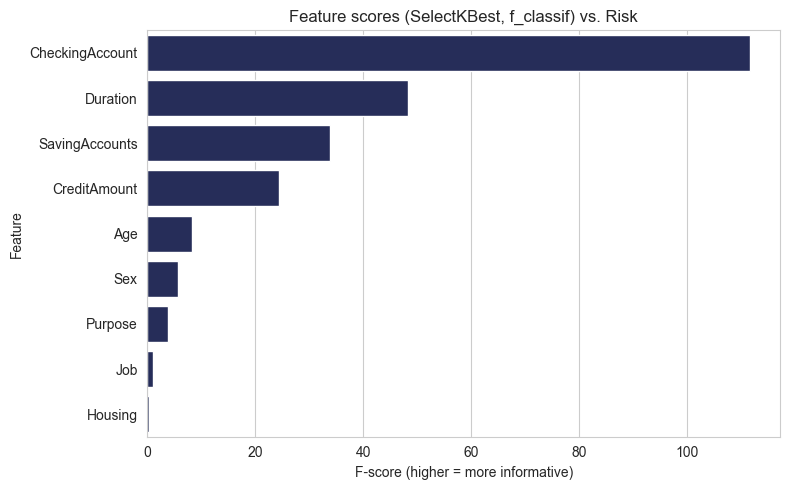

In [51]:
# Bar chart of feature scores -- the taller the bar, the more informative the
# feature looks with respect to Risk, based purely on this statistical test.
plt.figure(figsize=(8, 5))
sns.barplot(data=feature_scores, x="Score", y="Feature", color="#1E2761")
plt.title("Feature scores (SelectKBest, f_classif) vs. Risk")
plt.xlabel("F-score (higher = more informative)")
plt.tight_layout()
plt.show()

# Reminder: this ranking is a PREPROCESSING step, not a trained model. It helps
# guide which features to prioritize when modeling starts -- it does not predict
# anything by itself.

<div dir="rtl">

**ملاحظتي:** الرسمة بتوضح ترتيب أهمية الـ features. هاي خطوة تجهيز بس، مش موديل، وبتساعدني أعرف أي أعمدة أركز عليها لما أبني الموديل بالمرحلة الجاية.

</div>

---

**Prepared by:** Tiba Zakarnah
**Student ID:** 238003